In [1]:
# Load libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df= pd.read_csv(r"C:\Users\ADMIN\Desktop\Protein Stability\Data\4_fireprotDB_bestpH.csv")
df.head(3)

,Unnamed: 0,experiment_id,protein_name,uniprot_id,pdb_id,chain,position,wild_type,mutation,ddG,...,hsw_job_id,datasets,sequence,pdb_id_corrected,dupe_detector,pdb_position,pdb_sequence,oligomeric_state,structure_method,resolution
0,23,LL000714,Immunoglobulin G-binding protein G,P06654,1PGA|1EM7|2GB1,A,1,M,A,-0.14,...,2i1nqi,NaN,MEKEKKVKYFLRKSAFGLASVSAAFLVGSTVFAVDSPIEDTPIIRN...,1PGA,1PGA-A-0-M-P06654,0,MTYKLILNGKTLKGETTTEAVDAATAEKVFKQYANDNGVDGEWTYD...,monomer,x-ray diffraction,NaN
1,24,LL000715,Immunoglobulin G-binding protein G,P06654,1PGA|1EM7|2GB1,A,1,M,D,-0.38,...,2i1nqi,NaN,MEKEKKVKYFLRKSAFGLASVSAAFLVGSTVFAVDSPIEDTPIIRN...,1PGA,1PGA-D-0-M-P06654,0,MTYKLILNGKTLKGETTTEAVDAATAEKVFKQYANDNGVDGEWTYD...,monomer,x-ray diffraction,NaN
2,25,LL000716,Immunoglobulin G-binding protein G,P06654,1PGA|1EM7|2GB1,A,1,M,E,-0.64,...,2i1nqi,NaN,MEKEKKVKYFLRKSAFGLASVSAAFLVGSTVFAVDSPIEDTPIIRN...,1PGA,1PGA-E-0-M-P06654,0,MTYKLILNGKTLKGETTTEAVDAATAEKVFKQYANDNGVDGEWTYD...,monomer,x-ray diffraction,NaN


In [11]:
print(f"Shape of Data: {df.shape}")

Shape of Data: (4997, 43)


In [18]:
df.columns.tolist()

['Unnamed: 0',
 'experiment_id',
 'protein_name',
 'uniprot_id',
 'pdb_id',
 'chain',
 'position',
 'wild_type',
 'mutation',
 'ddG',
 'dTm',
 'is_curated',
 'type',
 'derived_type',
 'interpro_families',
 'conservation',
 'is_essential',
 'correlated_positions',
 'is_back_to_consensus',
 'secondary_structure',
 'asa',
 'is_in_catalytic_pocket',
 'is_in_tunnel_bottleneck',
 'b_factor',
 'method',
 'method_details',
 'technique',
 'technique_details',
 'pH',
 'tm',
 'notes',
 'publication_doi',
 'publication_pubmed',
 'hsw_job_id',
 'datasets',
 'sequence',
 'pdb_id_corrected',
 'dupe_detector',
 'pdb_position',
 'pdb_sequence',
 'oligomeric_state',
 'structure_method',
 'resolution']

In [19]:
print(f"Info of Data: {df.info()}")

<class 'pandas.DataFrame'>
RangeIndex: 4997 entries, 0 to 4996
Data columns (total 43 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               4997 non-null   int64  
 1   experiment_id            4997 non-null   str    
 2   protein_name             4997 non-null   str    
 3   uniprot_id               4997 non-null   str    
 4   pdb_id                   4997 non-null   str    
 5   chain                    4997 non-null   str    
 6   position                 4997 non-null   int64  
 7   wild_type                4997 non-null   str    
 8   mutation                 4997 non-null   str    
 9   ddG                      3438 non-null   float64
 10  dTm                      1614 non-null   float64
 11  is_curated               4997 non-null   bool   
 12  type                     0 non-null      float64
 13  derived_type             0 non-null      float64
 14  interpro_families        4989 non-n

In [20]:
df.describe()

,Unnamed: 0,position,ddG,dTm,type,derived_type,conservation,correlated_positions,asa,b_factor,pH,tm,publication_pubmed,pdb_position,resolution
count,4997.000000,4997.000000,3438.000000,1614.000000,0.0,0.0,4309.000000,0.0,4465.000000,4355.000000,4808.000000,1956.000000,4.983000e+03,4997.000000,0.0
mean,3514.960776,138.231139,1.063233,-2.856037,NaN,NaN,4.980042,NaN,47.359263,18.238535,6.375611,50.481851,1.902531e+07,70.103262,NaN
std,2459.309657,134.033547,1.808050,6.271552,NaN,NaN,1.844732,NaN,45.250688,11.983678,1.556526,15.825786,9.805924e+06,62.989840,NaN
min,0.000000,1.000000,-8.640000,-53.000000,NaN,NaN,1.000000,NaN,0.000000,0.320000,2.000000,2.800000,1.304917e+06,0.000000,NaN
25%,1398.000000,66.000000,-0.100000,-5.500000,NaN,NaN,4.000000,NaN,4.590000,10.250000,6.000000,40.282500,1.039814e+07,24.000000,NaN
50%,3220.000000,116.000000,0.677500,-1.500000,NaN,NaN,5.000000,NaN,36.540000,15.220000,6.780000,51.900000,1.765658e+07,54.000000,NaN
75%,5231.000000,185.000000,1.950000,0.600000,NaN,NaN,6.000000,NaN,76.600000,23.750000,7.000000,61.100000,2.844907e+07,100.000000,NaN
max,10255.000000,1833.000000,12.000000,21.100000,NaN,NaN,9.000000,NaN,241.350000,118.860000,11.000000,97.000000,3.225888e+07,448.000000,NaN


In [21]:
# NUll values
print(f"Total no of blank values:{df.isnull().sum().sum()}")
# Duplicates value
print(f"Total no of duplicates values:{df.duplicated().sum().sum()}")

Total no of blank values:40516
Total no of duplicates values:18


In [12]:
print("\nStability measurement summary:")
print(df["ddG"].describe())


Stability measurement summary:
count    3438.000000
mean        1.063233
std         1.808050
min        -8.640000
25%        -0.100000
50%         0.677500
75%         1.950000
max        12.000000
Name: ddG, dtype: float64


#### `ddG` represents a change in folding free energy. Do not treat it as melting-temperature change. Confirm the dataset's sign convention before interpreting a positive or negative prediction.

In [23]:
df.head(1)

,Unnamed: 0,experiment_id,protein_name,uniprot_id,pdb_id,chain,position,wild_type,mutation,ddG,...,hsw_job_id,datasets,sequence,pdb_id_corrected,dupe_detector,pdb_position,pdb_sequence,oligomeric_state,structure_method,resolution
0,23,LL000714,Immunoglobulin G-binding protein G,P06654,1PGA|1EM7|2GB1,A,1,M,A,-0.14,...,2i1nqi,NaN,MEKEKKVKYFLRKSAFGLASVSAAFLVGSTVFAVDSPIEDTPIIRN...,1PGA,1PGA-A-0-M-P06654,0,MTYKLILNGKTLKGETTTEAVDAATAEKVFKQYANDNGVDGEWTYD...,monomer,x-ray diffraction,NaN


In [24]:
df.columns

Index(['Unnamed: 0', 'experiment_id', 'protein_name', 'uniprot_id', 'pdb_id',
       'chain', 'position', 'wild_type', 'mutation', 'ddG', 'dTm',
       'is_curated', 'type', 'derived_type', 'interpro_families',
       'conservation', 'is_essential', 'correlated_positions',
       'is_back_to_consensus', 'secondary_structure', 'asa',
       'is_in_catalytic_pocket', 'is_in_tunnel_bottleneck', 'b_factor',
       'method', 'method_details', 'technique', 'technique_details', 'pH',
       'tm', 'notes', 'publication_doi', 'publication_pubmed', 'hsw_job_id',
       'datasets', 'sequence', 'pdb_id_corrected', 'dupe_detector',
       'pdb_position', 'pdb_sequence', 'oligomeric_state', 'structure_method',
       'resolution'],
      dtype='str')

In [13]:
required = ['wild_type','mutation','pdb_id_corrected','pdb_position','ddG']
df = df[required].copy()

In [14]:
# clean the data
df = df.dropna(subset = required)
df.head(2)

,wild_type,mutation,pdb_id_corrected,pdb_position,ddG
0,M,A,1PGA,0,-0.14
1,M,D,1PGA,0,-0.38


In [15]:
# convert the coulmns in numerical values.-- ( "5"---> 5)

df["pdb_position"] = pd.to_numeric(df["pdb_position"], errors="coerce")
df['ddG']= pd.to_numeric(df['ddG'], errors= "coerce")


In [16]:
# checking the null values
df.isnull().sum()

wild_type           0
mutation            0
pdb_id_corrected    0
pdb_position        0
ddG                 0
dtype: int64

In [74]:
from sklearn.model_selection import GroupShuffleSplit # Splits by protein structure ID.
# from sklearn.model_selection import train_test_split --> Randomly splits mutation records.

from sklearn.compose import ColumnTransformer # important in pipeline
# ColumnTransformer allows you to preprocess different types of features correctly in one place.
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error, r2_score

In [17]:
# define features and target
X = df[['wild_type','mutation', 'pdb_position']]
y= df['ddG']

group = df['pdb_id_corrected'] # dentifies which rows belong to the same protein structure ID.
# multiple mutations may come from the same protein.
# and also prevent data leakage between training and testing sets

In [76]:
# Split by protein  

splitter = GroupShuffleSplit(n_splits =1, test_size =0.2, random_state =42)

train_idx, test_idx = next(splitter.split(X, y, groups=group))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

In [77]:
# Verify that split happen or not
print(f"training rows: {len(X_train)}")
print(f"testing rows: {len(X_test)}")

training rows: 3028
testing rows: 410


In [78]:
preprocessor = ColumnTransformer (
    transformers = [(
        "AA", OneHotEncoder(handle_unknown ="ignore"),
        ["wild_type", "mutation"] ),
        ("position", "passthrough" ,["pdb_position"])
    ])

In [79]:
# Define models
models = {"Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200,random_state=42),
    "SVR": SVR(kernel="rbf"),
    "XGBoost": XGBRegressor(n_estimators=200,max_depth=4,learning_rate=0.05,random_state=42)

}


In [80]:

results = []
trained_models = {}

# Train and evaluate each model
for name, regressor in models.items():

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

    # Train each model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Evaluate
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # storing the result
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = model

    print(f"\n{name}")
    print("MAE:", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2 Score:", round(r2, 4))


Linear Regression
MAE: 1.2004
RMSE: 1.5592
R2 Score: 0.0898

Random Forest
MAE: 1.2672
RMSE: 1.6608
R2 Score: -0.0328

SVR
MAE: 1.26
RMSE: 1.6505
R2 Score: -0.0199

XGBoost
MAE: 1.2417
RMSE: 1.5923
R2 Score: 0.0507


In [81]:
# Compare the actual values with prediction values
results = pd.DataFrame({"Actual_value": y_test, "Predict_value" : y_pred})
results.head(10)

,Actual_value,Predict_value
845,-0.580,1.116081
846,0.090,1.097594
847,2.265,0.637625
848,-0.050,0.990318
849,0.310,0.990318
850,2.200,1.342339
851,-0.190,0.634711
852,-0.100,0.657001
853,-1.290,0.597986
854,1.000,0.127581


In [63]:

print("====Final Model Comparison====")
Performance_result = pd.DataFrame(results)
Performance_result = Performance_result.sort_values(by ="MAE", ascending= True)

print(Performance_result)


====Final Model Comparison====
               Model       MAE      RMSE  R2 Score
0  Linear Regression  1.200384  1.559206  0.089758
3            XGBoost  1.241693  1.592316  0.050690
2                SVR  1.259975  1.650468 -0.019915
1      Random Forest  1.267160  1.660838 -0.032772


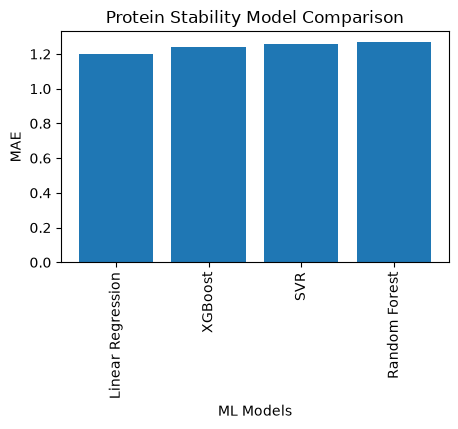

In [67]:
# Visualize the comparison
plt.figure(figsize=(5,3))

plt.bar(Performance_result['Model'], Performance_result['MAE'])
plt.title("Protein Stability Model Comparison")
plt.xlabel("ML Models")
plt.ylabel("MAE")
plt.xticks(rotation=90)
plt.show()

In [69]:
# Select the best model
best_model_name = Performance_result.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model based on MAE:", best_model_name)

Best model based on MAE: Linear Regression


## Linear Regression is best because:
#### Lowest MAE: 1.2004: Its average absolute prediction error is the smallest among the four models.
#### Lowest RMSE: 1.5592: It also has the lowest root mean squared error, indicating the best test-set performance by this metric.
#### R²: 0.0898: It explains only about 9% of the variation in the test targets. This is a weak result.

In [82]:
# Save model
import joblib

joblib.dump(model, "Protein_stability_model.pkl")
print("Model Save Successfully")

Model Save Successfully


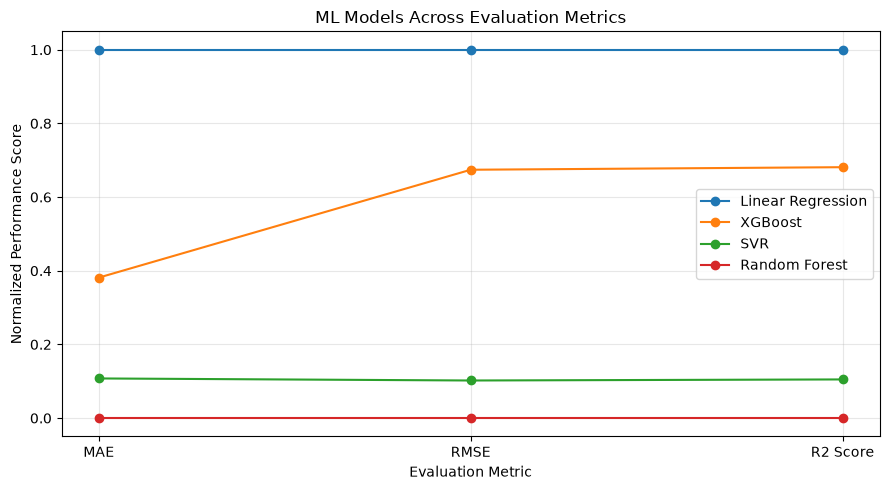

In [83]:

import matplotlib.pyplot as plt

line_df = Performance_result.set_index("Model")[
    ["MAE", "RMSE", "R2 Score"]
].copy()

# Normalize each metric
line_scores = (
    (line_df - line_df.min()) /
    (line_df.max() - line_df.min()).replace(0, 1)
)

# Reverse error metrics so higher means better
line_scores["MAE"] = 1 - line_scores["MAE"]
line_scores["RMSE"] = 1 - line_scores["RMSE"]

plt.figure(figsize=(9, 5))

for model_name, row in line_scores.iterrows():
    plt.plot(
        row.index,
        row.values,
        marker="o",
        label=model_name
    )

plt.xlabel("Evaluation Metric")
plt.ylabel("Normalized Performance Score")
plt.title("ML Models Across Evaluation Metrics")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


4. How to explain this in an interview

You can say:
"I compared four regression algorithms: Linear Regression, Random Forest, Support Vector Regression, and XGBoost. I evaluated them using MAE, RMSE, and R². Linear Regression performed best on my test set, with an MAE of 1.20, an RMSE of 1.56, and an R² of 0.09. However, the low R² indicated that the models were not capturing protein stability changes effectively. My next step would be to improve the sequence-derived features and validate the models using cross-validation grouped by protein."

My final recommendation: Keep Linear Regression as your current baseline winner, but don't present it as a reliable protein stability predictor until its performance improves and is validated.